[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/09-system-design/02_load-balancing.ipynb)

*System Design · Notebook 2 of 10*

# Load Balancing, Routing & CDNs

Spread traffic and survive failures: round robin, weighted and least-connections balancing, sticky hashing, consistent hashing with virtual nodes, health checks, power of two choices, path routing, DNS TTLs, CDN hit ratios, geo routing, autoscaling, rolling and blue/green deploys, and regional failover.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** A load balancer is the host at a busy restaurant: it seats each guest at a free table and stops seating at a table whose waiter went home.

**What interviewers really test here:** Algorithms, L4 vs L7, health checks, consistent hashing with virtual nodes, CDNs and DNS, global failover, autoscaling and safe deploys.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. Why load balancers exist *(Basics)*
- [ ] 2. Layer 4 vs layer 7, and health checks *(Core)*
- [ ] 3. Consistent hashing *(Core)*
- [ ] 4. DNS, CDNs and global traffic *(Core)*
- [ ] 5. Elasticity and safe releases *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import math
import json
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Where load balancing happens

| Layer | Example | Decides by |
| --- | --- | --- |
| DNS / global | geo-DNS, anycast | user location, region health |
| Edge | CDN | cache key, edge location |
| L4 | network load balancer | IP and port |
| L7 | nginx, Envoy, API gateway | path, headers, cookies |
| Client-side | service mesh, gRPC | service discovery + algorithm |

### Single points of failure

A load balancer itself can fail, so run it in pairs (active-passive with a floating IP) or as a managed service spread across zones. Check every box in your diagram: if it has only one copy, it's a single point of failure — say how you'd remove it.

---
# Part 2: Lessons, step by step

## Lesson 1: Why load balancers exist

*Level: Basics*

One server has limits (CPU, memory, connections) and fails sometimes. A **load balancer** sits in front of many identical servers, spreads requests across them, and stops sending traffic to servers that fail health checks. This only works if servers are **stateless**: no user session kept in a server's memory — put sessions in a shared store (Redis, a database) or a signed cookie.



| Algorithm | How | Good for |
| --- | --- | --- |
| Round robin | next server in turn | similar servers, similar requests |
| Weighted round robin | more turns for bigger servers | mixed server sizes, canaries |
| Least connections | fewest active requests | long or uneven requests |
| Power of two choices | sample two, pick the less loaded | large fleets, near-optimal and cheap |
| Hashing (IP / key) | same client → same server | caches, sticky needs |

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q10](#q10), [Q11](#q11), [Q14](#q14), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 2: Layer 4 vs layer 7, and health checks

*Level: Core*

An **L4** balancer routes TCP/UDP connections by IP and port — fast and protocol-agnostic. An **L7** balancer understands HTTP: it can route by path or header (`/api/v2/*` → new service), terminate TLS, retry, and rate-limit. Most web systems use L7 (nginx, Envoy, cloud application load balancers), often behind an L4 layer.



**Health checks** probe each server; mark it down after several consecutive failures and back up after several passes (hysteresis), so a single blip doesn't make it flap in and out. When removing a server, **drain** it first: stop new requests and let in-flight ones finish.

**✏️ Your turn:** you now have what you need for [Q4](#q4), [Q13](#q13), [Q3](#q3), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 3: Consistent hashing

*Level: Core*

Caches and sharded stores need the same key to land on the same node. `hash(key) % N` works until N changes — then almost every key moves, and the cache empties. **Consistent hashing** places nodes on a ring of hash values; a key belongs to the first node clockwise from its hash. Adding or removing a node only moves the keys in that node's arc — about 1/N of them.



With only a few points, arcs are uneven; giving every node many **virtual nodes** (100+ points on the ring) evens out the load and lets bigger machines take more points. Used by Cassandra, DynamoDB, Memcached clients and many load balancers.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

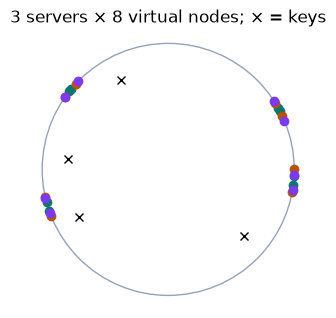

In [2]:
import zlib
import matplotlib.pyplot as plt


def ring_picture():
    import math
    servers = ["cache-a", "cache-b", "cache-c"]
    fig, ax = plt.subplots(figsize=(3.6, 3.6))
    ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="#94a3b8"))
    colors = {"cache-a": "#0f766e", "cache-b": "#b45309", "cache-c": "#7c3aed"}
    for s in servers:
        for i in range(8):
            angle = zlib.crc32(f"{s}#{i}".encode()) / 2 ** 32 * 2 * math.pi
            ax.plot(math.cos(angle), math.sin(angle), "o", color=colors[s])
    for k in ["user:1", "user:2", "photo:9", "cart:7"]:
        angle = zlib.crc32(k.encode()) / 2 ** 32 * 2 * math.pi
        ax.plot(0.8 * math.cos(angle), 0.8 * math.sin(angle), "x", color="black")
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title("3 servers × 8 virtual nodes; × = keys")


ring_picture()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q12](#q12), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 4: DNS, CDNs and global traffic

*Level: Core*

- **DNS** maps names to IPs and is cached for its TTL — lower the TTL before a planned migration so the change spreads quickly.
- A **CDN** caches static (and some dynamic) content at edge locations near users: lower latency and far less origin load. Origin load = requests × (1 − hit ratio), so going from a 90% to a 98% hit ratio cuts origin traffic five-fold.
- **Global load balancing** sends users to the nearest healthy region (geo-DNS or anycast) and fails over to the next region when one is down.

**✏️ Your turn:** you now have what you need for [Q5](#q5), [Q15](#q15), [Q6](#q6), [Q16](#q16), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 5: Elasticity and safe releases

*Level: Advanced*

- **Autoscaling**: target tracking keeps a metric (CPU, requests per instance, queue depth) near a target by adding or removing instances; scale out fast, scale in slowly (cooldowns) to avoid oscillation.
- **Rolling deploys** replace servers in batches while keeping enough capacity serving.
- **Blue/green and canary** releases shift a small percentage of traffic to the new version first, watch error rates, and roll back instantly if they rise.

**✏️ Your turn:** you now have what you need for [Q17](#q17), [Q7](#q7), [Q8](#q8). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [3]:
import zlib

H = lambda s: zlib.crc32(s.encode())

import bisect


<a id="q1"></a>
### Q1. Round Robin

🟢 Warm-up · *The simplest balancer*

Assign requests in order to servers in turn. Return the server for each request.

**Examples**

- `servers = ['a', 'b', 'c'], requests = 7` → `['a', 'b', 'c', 'a', 'b', 'c', 'a']`

In [ ]:
def round_robin(servers, requests):
    """
    Assign requests in order to servers in turn. Return the server for each
    request.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(round_robin, [
    ((['a', 'b', 'c'], 7), ['a', 'b', 'c', 'a', 'b', 'c', 'a']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A counter that wraps around.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Index with `i % n`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A counter that wraps around.

```python
def round_robin(servers, requests):
    out, i = [], 0
    for _ in range(requests):
        out.append(servers[i])
        i += 1
        if i == len(servers):
            i = 0
    return out
```

**Cost:** O(r) time, O(r) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Index with `i % n`.

```python
def round_robin(servers, requests):
    return [servers[i % len(servers)] for i in range(requests)]
```

**Cost:** O(r) time, O(r) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A counter that wraps around. That costs O(r) time and O(r) space."

"I can do better: Index with `i % n`. That's O(r) time and O(r) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/round-robin)

<a id="q2"></a>
### Q2. Sticky Routing by Client IP

🟢 Warm-up · *Same client, same server*

Route each client IP to `servers[crc32(ip) % n]`. Return the mapping, and how many of the clients move if one server is added at the end.

**Examples**

- `ips = ['10.0.0.1', '10.0.0.2', '10.0.0.3', '10.0.0.4', '10.0.0.5', '10.0.0.6'], servers = ['s1', 's2', 's3']` → `({'10.0.0.1': 's3', '10.0.0.2': 's3', '10.0.0.3': 's3', '10.0.0.4': 's1', '10.0.0.5': 's3', '10.0.0.6': 's3'}, 4)`

In [ ]:
def ip_hash(ips, servers):
    """
    Route each client IP to servers[crc32(ip) % n]. Return the mapping, and how
    many of the clients move if one server is added at the end.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ip_hash, [
    ((['10.0.0.1', '10.0.0.2', '10.0.0.3', '10.0.0.4', '10.0.0.5', '10.0.0.6'], ['s1', 's2', 's3']), ({'10.0.0.1': 's3', '10.0.0.2': 's3', '10.0.0.3': 's3', '10.0.0.4': 's1', '10.0.0.5': 's3', '10.0.0.6': 's3'}, 4)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop twice: before and after.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Comprehensions with the hash helper `H`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loop twice: before and after.

```python
def ip_hash(ips, servers):
    before, moved = {}, 0
    bigger = servers + ["s_new"]
    for ip in ips:
        before[ip] = servers[zlib.crc32(ip.encode()) % len(servers)]
        if bigger[zlib.crc32(ip.encode()) % len(bigger)] != before[ip]:
            moved += 1
    return (before, moved)
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Comprehensions with the hash helper `H`.

```python
def ip_hash(ips, servers):
    bigger = servers + ["s_new"]
    before = {ip: servers[H(ip) % len(servers)] for ip in ips}
    return (before, sum(bigger[H(ip) % len(bigger)] != before[ip] for ip in ips))
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop twice: before and after. That costs O(c) time and O(c) space."

"I can do better: Comprehensions with the hash helper `H`. That's O(c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/sticky-routing-by-client-ip)

<a id="q3"></a>
### Q3. Fail Over to a Healthy Server

🟢 Warm-up · *Skip the dead ones*

Route each request round-robin, but skip servers marked down (try the next one). Return the server per request, or None if all are down.

**Examples**

- `servers = ['a', 'b', 'c', 'd'], down = {'b', 'd'}, requests = 5` → `['a', 'c', 'a', 'c', 'a']`
- `servers = ['a', 'b'], down = {'b', 'a'}, requests = 2` → `[None, None]`

In [ ]:
def failover(servers, down, requests):
    """
    Route each request round-robin, but skip servers marked down (try the next
    one). Return the server per request, or None if all are down.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(failover, [
    ((['a', 'b', 'c', 'd'], {'b', 'd'}, 5), ['a', 'c', 'a', 'c', 'a']),
    ((['a', 'b'], {'b', 'a'}, 2), [None, None]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Advance the pointer until an up server is found.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Filter healthy servers once, then index.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Advance the pointer until an up server is found.

```python
def failover(servers, down, requests):
    out, i = [], 0
    for _ in range(requests):
        chosen = None
        for _ in range(len(servers)):
            s = servers[i % len(servers)]
            i += 1
            if s not in down:
                chosen = s
                break
        out.append(chosen)
    return out
```

**Cost:** O(r · n) time, O(r) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Filter healthy servers once, then index.

```python
def failover(servers, down, requests):
    healthy = [s for s in servers if s not in down]
    return [healthy[i % len(healthy)] if healthy else None for i in range(requests)]
```

**Cost:** O(r + n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Advance the pointer until an up server is found. That costs O(r · n) time and O(r) space."

"I can do better: Filter healthy servers once, then index. That's O(r + n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/fail-over-to-a-healthy-server)

<a id="q4"></a>
### Q4. Route by Path (Layer 7)

🟢 Warm-up · *Longest prefix wins*

An L7 load balancer routes by URL path: pick the backend whose prefix in `ROUTES` is the longest one the path starts with.

**Examples**

- `paths = ['/api/users/7', '/api/v2/orders', '/static/logo.png', '/about']` → `['api-pool', 'api-v2-pool', 'cdn-origin', 'web-pool']`

In [ ]:
ROUTES = {"/api/": "api-pool", "/api/v2/": "api-v2-pool", "/static/": "cdn-origin", "/": "web-pool"}

def route_path(paths):
    """
    An L7 load balancer routes by URL path: pick the backend whose prefix in
    ROUTES is the longest one the path starts with.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(route_path, [
    ((['/api/users/7', '/api/v2/orders', '/static/logo.png', '/about'],), ['api-pool', 'api-v2-pool', 'cdn-origin', 'web-pool']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Check every prefix and keep the longest match.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`max` over the matching prefixes by length.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Check every prefix and keep the longest match.

```python
def route_path(paths):
    out = []
    for p in paths:
        best = ""
        for prefix in ROUTES:
            if p.startswith(prefix) and len(prefix) > len(best):
                best = prefix
        out.append(ROUTES[best])
    return out
```

**Cost:** O(p · r) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `max` over the matching prefixes by length.

```python
def route_path(paths):
    return [ROUTES[max((r for r in ROUTES if p.startswith(r)), key=len)] for p in paths]
```

**Cost:** O(p · r) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Check every prefix and keep the longest match. That costs O(p · r) time and O(1) space."

"I can do better: `max` over the matching prefixes by length. That's O(p · r) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/route-by-path-layer-7)

<a id="q5"></a>
### Q5. How Long Until DNS Changes Everywhere?

🟢 Warm-up · *TTLs*

You change a DNS record at time 0. Resolvers cached it at the given times (seconds before the change) with TTL `ttl`. Return the time (seconds after the change) when the last resolver's cache expires. Lower TTLs before planned migrations.

**Examples**

- `ages = [5, 120, 299, 30], ttl = 300` → `295`
- `ages = [5, 20], ttl = 60` → `55`

In [ ]:
def dns_settle(ages, ttl):
    """
    You change a DNS record at time 0. Resolvers cached it at the given times
    (seconds before the change) with TTL ttl. Return the time (seconds after the
    change) when the last resolver's cache expires. Lower TTLs before planned
    migrations.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(dns_settle, [
    (([5, 120, 299, 30], 300), 295),
    (([5, 20], 60), 55),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each, remaining = ttl − age; take the max.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`max` over a generator.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** For each, remaining = ttl − age; take the max.

```python
def dns_settle(ages, ttl):
    worst = 0
    for a in ages:
        remaining = ttl - a
        if remaining > worst:
            worst = remaining
    return worst
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `max` over a generator.

```python
def dns_settle(ages, ttl):
    return max(0, max(ttl - a for a in ages))
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each, remaining = ttl − age; take the max. That costs O(n) time and O(1) space."

"I can do better: `max` over a generator. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/how-long-until-dns-changes-everywhere)

<a id="q6"></a>
### Q6. Does the CDN Speed Things Up?

🟢 Warm-up · *Weighted latency*

A hit at the edge takes `edge_ms`; a miss goes to the origin and takes `origin_ms`. Return the average latency (ms, rounded to 1) for each hit ratio in `ratios`.

**Examples**

- `edge = 20, origin = 180, ratios = [0.0, 0.5, 0.9, 0.98]` → `[180.0, 100.0, 36.0, 23.2]`

In [ ]:
def cdn_latency(edge, origin, ratios):
    """
    A hit at the edge takes edge_ms; a miss goes to the origin and takes
    origin_ms. Return the average latency (ms, rounded to 1) for each hit ratio
    in ratios.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cdn_latency, [
    ((20, 180, [0.0, 0.5, 0.9, 0.98]), [180.0, 100.0, 36.0, 23.2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A weighted average in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A comprehension.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A weighted average in a loop.

```python
def cdn_latency(edge, origin, ratios):
    out = []
    for h in ratios:
        out.append(round(h * edge + (1 - h) * origin, 1))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A comprehension.

```python
def cdn_latency(edge, origin, ratios):
    return [round(origin - h * (origin - edge), 1) for h in ratios]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A weighted average in a loop. That costs O(n) time and O(n) space."

"I can do better: A comprehension. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/does-the-cdn-speed-things-up)

<a id="q7"></a>
### Q7. Rolling Deploy Batches

🟢 Warm-up · *Keep capacity during a release*

Update servers in batches so that at least `min_pct`% stay serving. Return `(largest batch size, number of batches)` for `n` servers.

**Examples**

- `n = 20, min_pct = 75` → `(5, 4)`
- `n = 7, min_pct = 90` → `(1, 7)`

In [ ]:
def rolling(n, min_pct):
    """
    Update servers in batches so that at least min_pct% stay serving. Return
    (largest batch size, number of batches) for n servers.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(rolling, [
    ((20, 75), (5, 4)),
    ((7, 90), (1, 7)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Grow the batch while capacity stays above the floor.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Floor arithmetic, at least 1 per batch.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Grow the batch while capacity stays above the floor.

```python
def rolling(n, min_pct):
    batch = 1
    while (n - (batch + 1)) / n * 100 >= min_pct:
        batch += 1
    batches = n // batch + (1 if n % batch else 0)
    return (batch, batches)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Floor arithmetic, at least 1 per batch.

```python
def rolling(n, min_pct):
    batch = max(1, math.floor(round(n * (100 - min_pct) / 100, 9)))
    return (batch, math.ceil(n / batch))
```

**Cost:** O(1) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Grow the batch while capacity stays above the floor. That costs O(n) time and O(1) space."

"I can do better: Floor arithmetic, at least 1 per batch. That's O(1) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/rolling-deploy-batches)

<a id="q8"></a>
### Q8. Shift Traffic Blue → Green

🟢 Warm-up · *Progressive rollout*

Move traffic to the new (green) version in steps of `pcts`%. At each step, if the green error rate exceeds `max_err`, roll back to 0% and stop. Return the green % after each step that ran.

**Examples**

- `pcts = [1, 5, 25, 50, 100], errs = [0.1, 0.2, 0.3, 0.2, 0.1], max_err = 1.0` → `[1, 5, 25, 50, 100]`
- `pcts = [1, 5, 25, 50, 100], errs = [0.1, 0.2, 2.5, 0.2, 0.1], max_err = 1.0` → `[1, 5, 0]`

In [ ]:
def blue_green(pcts, errs, max_err):
    """
    Move traffic to the new (green) version in steps of pcts%. At each step, if
    the green error rate exceeds max_err, roll back to 0% and stop. Return the
    green % after each step that ran.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(blue_green, [
    (([1, 5, 25, 50, 100], [0.1, 0.2, 0.3, 0.2, 0.1], 1.0), [1, 5, 25, 50, 100]),
    (([1, 5, 25, 50, 100], [0.1, 0.2, 2.5, 0.2, 0.1], 1.0), [1, 5, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

A loop with an early stop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`zip` and a for-else.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** A loop with an early stop.

```python
def blue_green(pcts, errs, max_err):
    out = []
    for i in range(len(pcts)):
        if errs[i] > max_err:
            out.append(0)
            break
        out.append(pcts[i])
    return out
```

**Cost:** O(s) time, O(s) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `zip` and a for-else.

```python
def blue_green(pcts, errs, max_err):
    out = []
    for p, e in zip(pcts, errs):
        out.append(0 if e > max_err else p)
        if e > max_err:
            break
    return out
```

**Cost:** O(s) time, O(s) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: A loop with an early stop. That costs O(s) time and O(s) space."

"I can do better: `zip` and a for-else. That's O(s) time and O(s) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/shift-traffic-blue-green)

<a id="q9"></a>
### Q9. Drain Connections Before Removing a Server

🟢 Warm-up · *Graceful shutdown*

Before removing a server, the balancer stops sending it new requests and waits up to `timeout` seconds for in-flight ones (given as seconds remaining). Return `(requests finished cleanly, requests cut off, seconds the drain took)`.

**Examples**

- `remaining = [0.2, 3.5, 12.0, 0.8, 45.0], timeout = 30` → `(4, 1, 30)`
- `remaining = [1.0, 2.0], timeout = 30` → `(2, 0, 2.0)`

In [ ]:
def drain(remaining, timeout):
    """
    Before removing a server, the balancer stops sending it new requests and
    waits up to timeout seconds for in-flight ones (given as seconds remaining).
    Return (requests finished cleanly, requests cut off, seconds the drain
    took).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(drain, [
    (([0.2, 3.5, 12.0, 0.8, 45.0], 30), (4, 1, 30)),
    (([1.0, 2.0], 30), (2, 0, 2.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count with a loop and track the longest finished request.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Comprehensions and `min`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count with a loop and track the longest finished request.

```python
def drain(remaining, timeout):
    done = cut = 0
    longest = 0
    for r in remaining:
        if r <= timeout:
            done += 1
            longest = max(longest, r)
        else:
            cut += 1
    took = timeout if cut else longest
    return (done, cut, took)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Comprehensions and `min`.

```python
def drain(remaining, timeout):
    done = [r for r in remaining if r <= timeout]
    cut = len(remaining) - len(done)
    return (len(done), cut, timeout if cut else max(done, default=0))
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count with a loop and track the longest finished request. That costs O(n) time and O(1) space."

"I can do better: Comprehensions and `min`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/drain-connections-before-removing-a-server)

<a id="q10"></a>
### Q10. Weighted Round Robin

🟡 Interview standard · *Bigger servers get more*

Smooth weighted round robin (as nginx does): each turn, add every server's weight to its current score, pick the highest (first on ties), then subtract the total weight from the winner. Return the order of picks.

**Examples**

- `weights = {'a': 5, 'b': 1, 'c': 1}, requests = 7` → `['a', 'a', 'b', 'a', 'c', 'a', 'a']`
- `weights = {'big': 3, 'small': 1}, requests = 8` → `['big', 'big', 'small', 'big', 'big', 'big', 'small', 'big']`

In [ ]:
def weighted_rr(weights, requests):
    """
    Smooth weighted round robin (as nginx does): each turn, add every server's
    weight to its current score, pick the highest (first on ties), then subtract
    the total weight from the winner. Return the order of picks.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(weighted_rr, [
    (({'a': 5, 'b': 1, 'c': 1}, 7), ['a', 'a', 'b', 'a', 'c', 'a', 'a']),
    (({'big': 3, 'small': 1}, 8), ['big', 'big', 'small', 'big', 'big', 'big', 'small', 'big']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track scores in a dict.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same algorithm with `max` over the scores.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Track scores in a dict.

```python
def weighted_rr(weights, requests):
    current = {s: 0 for s in weights}
    total = sum(weights.values())
    out = []
    for _ in range(requests):
        best = None
        for s, w in weights.items():
            current[s] += w
            if best is None or current[s] > current[best]:
                best = s
        current[best] -= total
        out.append(best)
    return out
```

**Cost:** O(r · n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same algorithm with `max` over the scores.

```python
def weighted_rr(weights, requests):
    current, total, out = dict.fromkeys(weights, 0), sum(weights.values()), []
    for _ in range(requests):
        for s in weights:
            current[s] += weights[s]
        best = max(weights, key=current.get)
        current[best] -= total
        out.append(best)
    return out
```

**Cost:** O(r · n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track scores in a dict. That costs O(r · n) time and O(n) space."

"I can do better: Same algorithm with `max` over the scores. That's O(r · n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/weighted-round-robin)

<a id="q11"></a>
### Q11. Least Connections

🟡 Interview standard · *Send work to the least busy*

Requests arrive one per second (at t = 0, 1, 2, …) and take `durations[i]` seconds. Each goes to the server with the fewest active requests at that moment (lowest index on ties). Return the server index chosen for each request.

**Examples**

- `durations = [10, 1, 1, 1, 1, 10, 1], n = 2` → `[0, 1, 1, 1, 1, 1, 0]`

In [ ]:
import heapq

def least_conn(durations, n):
    """
    Requests arrive one per second (at t = 0, 1, 2, …) and take durations[i]
    seconds. Each goes to the server with the fewest active requests at that
    moment (lowest index on ties). Return the server index chosen for each
    request.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(least_conn, [
    (([10, 1, 1, 1, 1, 10, 1], 2), [0, 1, 1, 1, 1, 1, 0]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each request, count active requests per server by scanning.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Keep each server's finish times in a min-heap and pop the finished ones.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** For each request, count active requests per server by scanning.

```python
def least_conn(durations, n):
    busy = [[] for _ in range(n)]
    out = []
    for t, d in enumerate(durations):
        active = [sum(1 for end in busy[s] if end > t) for s in range(n)]
        s = active.index(min(active))
        busy[s].append(t + d)
        out.append(s)
    return out
```

**Cost:** O(r²) time, O(r) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Keep each server's finish times in a min-heap and pop the finished ones.

```python
def least_conn(durations, n):
    ends = [[] for _ in range(n)]
    out = []
    for t, d in enumerate(durations):
        for h in ends:
            while h and h[0] <= t:
                heapq.heappop(h)
        s = min(range(n), key=lambda i: len(ends[i]))
        heapq.heappush(ends[s], t + d)
        out.append(s)
    return out
```

**Cost:** O(r log r) time, O(r) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each request, count active requests per server by scanning. That costs O(r²) time and O(r) space."

"I can do better: Keep each server's finish times in a min-heap and pop the finished ones. That's O(r log r) time and O(r) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/least-connections)

<a id="q12"></a>
### Q12. Consistent Hashing Lookup

🟡 Interview standard · *The hash ring*

Place each server on a ring at position crc32(name). A key goes to the first server at or after crc32(key) going clockwise (wrapping around). Return the server for each key.

**Examples**

- `servers = ['cache-a', 'cache-b', 'cache-c'], keys = ['user:1', 'user:2', 'user:3', 'photo:9', 'cart:7']` → `{'user:1': 'cache-c', 'user:2': 'cache-b', 'user:3': 'cache-b', 'photo:9': 'cache-c', 'cart:7': 'cache-b'}`

In [ ]:
def ring_lookup(servers, keys):
    """
    Place each server on a ring at position crc32(name). A key goes to the first
    server at or after crc32(key) going clockwise (wrapping around). Return the
    server for each key.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ring_lookup, [
    ((['cache-a', 'cache-b', 'cache-c'], ['user:1', 'user:2', 'user:3', 'photo:9', 'cart:7']), {'user:1': 'cache-c', 'user:2': 'cache-b', 'user:3': 'cache-b', 'photo:9': 'cache-c', 'cart:7': 'cache-b'}),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each key scan all servers for the smallest position ≥ the key's (else the smallest overall).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Sort positions once and use `bisect`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** For each key scan all servers for the smallest position ≥ the key's (else the smallest overall).

```python
def ring_lookup(servers, keys):
    out = {}
    for k in keys:
        hk = zlib.crc32(k.encode())
        best = None
        for s in servers:
            hs = zlib.crc32(s.encode())
            if hs >= hk and (best is None or hs < zlib.crc32(best.encode())):
                best = s
        if best is None:
            best = min(servers, key=lambda s: zlib.crc32(s.encode()))
        out[k] = best
    return out
```

**Cost:** O(k · n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Sort positions once and use `bisect`.

```python
def ring_lookup(servers, keys):
    ring = sorted((H(s), s) for s in servers)
    pos = [p for p, _ in ring]
    return {k: ring[bisect.bisect_left(pos, H(k)) % len(ring)][1] for k in keys}
```

**Cost:** O((n + k) log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each key scan all servers for the smallest position ≥ the key's (else the smallest overall). That costs O(k · n) time and O(n) space."

"I can do better: Sort positions once and use `bisect`. That's O((n + k) log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/consistent-hashing-lookup)

<a id="q13"></a>
### Q13. Health Checks With Hysteresis

🟡 Interview standard · *Don't flap*

A balancer marks a server down after `fail_n` consecutive failed checks and back up after `ok_n` consecutive passes. It starts up. Given check results (True = pass), return the status after each check ('up' / 'down').

**Examples**

- `checks = [True, False, False, True, False, False, False, True, True, False, True, True, True], fail_n = 3, ok_n = 2` → `['up', 'up', 'up', 'up', 'up', 'up', 'down', 'down', 'up', 'up', 'up', 'up', 'up']`

In [ ]:
def health(checks, fail_n, ok_n):
    """
    A balancer marks a server down after fail_n consecutive failed checks and
    back up after ok_n consecutive passes. It starts up. Given check results
    (True = pass), return the status after each check ('up' / 'down').
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(health, [
    (([True, False, False, True, False, False, False, True, True, False, True, True, True], 3, 2), ['up', 'up', 'up', 'up', 'up', 'up', 'down', 'down', 'up', 'up', 'up', 'up', 'up']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two counters and an if-chain.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same state machine, written compactly.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two counters and an if-chain.

```python
def health(checks, fail_n, ok_n):
    status, fails, oks, out = "up", 0, 0, []
    for ok in checks:
        if ok:
            oks += 1
            fails = 0
        else:
            fails += 1
            oks = 0
        if status == "up" and fails >= fail_n:
            status = "down"
        elif status == "down" and oks >= ok_n:
            status = "up"
        out.append(status)
    return out
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same state machine, written compactly.

```python
def health(checks, fail_n, ok_n):
    status, run, out = "up", 0, []
    for i, ok in enumerate(checks):
        run = run + 1 if i and checks[i - 1] == ok else 1
        if status == "up" and not ok and run >= fail_n:
            status = "down"
        elif status == "down" and ok and run >= ok_n:
            status = "up"
        out.append(status)
    return out
```

**Cost:** O(c) time, O(c) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two counters and an if-chain. That costs O(c) time and O(c) space."

"I can do better: Same state machine, written compactly. That's O(c) time and O(c) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/health-checks-with-hysteresis)

<a id="q14"></a>
### Q14. Power of Two Choices

🟡 Interview standard · *Nearly optimal, almost free*

For each request you sample two servers (given as `pairs`) and send it to the one with fewer requests so far (the first on ties). Compare with sending to only the first sample. Return `(max load with one choice, max load with two choices)`.

**Examples**

- `pairs = [(0, 1), (0, 2), (0, 3), (1, 0), (0, 2), (0, 1), (3, 0), (0, 2), (1, 3), (0, 2), (2, 1), (0, 3)], n = 4` → `(8, 3)`

In [ ]:
def two_choices(pairs, n):
    """
    For each request you sample two servers (given as pairs) and send it to the
    one with fewer requests so far (the first on ties). Compare with sending to
    only the first sample. Return (max load with one choice, max load with two
    choices).
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(two_choices, [
    (([(0, 1), (0, 2), (0, 3), (1, 0), (0, 2), (0, 1), (3, 0), (0, 2), (1, 3), (0, 2), (2, 1), (0, 3)], 4), (8, 3)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Two simulations with load lists.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with `min` over the pair.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Two simulations with load lists.

```python
def two_choices(pairs, n):
    one, two = [0] * n, [0] * n
    for a, b in pairs:
        one[a] += 1
        if two[b] < two[a]:
            two[b] += 1
        else:
            two[a] += 1
    return (max(one), max(two))
```

**Cost:** O(r) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with `min` over the pair.

```python
def two_choices(pairs, n):
    one, two = [0] * n, [0] * n
    for a, b in pairs:
        one[a] += 1
        two[min((a, b), key=lambda s: two[s])] += 1
    return (max(one), max(two))
```

**Cost:** O(r) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Two simulations with load lists. That costs O(r) time and O(n) space."

"I can do better: Same, with `min` over the pair. That's O(r) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/power-of-two-choices)

<a id="q15"></a>
### Q15. CDN Hit Ratio and Origin Load

🟡 Interview standard · *Edge caching*

Requests for objects arrive as `(time_s, object)`. The CDN edge keeps each object for `ttl` seconds after fetching it from the origin. Return `(origin fetches, hit ratio %)` rounded to 1.

**Examples**

- `requests = [(0, 'a'), (1, 'a'), (2, 'b'), (30, 'a'), (61, 'a'), (62, 'b'), (70, 'b')], ttl = 60` → `(4, 42.9)`

In [ ]:
def cdn(requests, ttl):
    """
    Requests for objects arrive as (time_s, object). The CDN edge keeps each
    object for ttl seconds after fetching it from the origin. Return (origin
    fetches, hit ratio %) rounded to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cdn, [
    (([(0, 'a'), (1, 'a'), (2, 'b'), (30, 'a'), (61, 'a'), (62, 'b'), (70, 'b')], 60), (4, 42.9)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Track each object's fetch time in a dict.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same, with `dict.get` and a default of −∞.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Track each object's fetch time in a dict.

```python
def cdn(requests, ttl):
    fetched, misses = {}, 0
    for t, obj in requests:
        if obj not in fetched or t - fetched[obj] >= ttl:
            misses += 1
            fetched[obj] = t
    return (misses, round((1 - misses / len(requests)) * 100, 1))
```

**Cost:** O(r) time, O(o) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same, with `dict.get` and a default of −∞.

```python
def cdn(requests, ttl):
    fetched, misses = {}, 0
    for t, obj in requests:
        if t - fetched.get(obj, -math.inf) >= ttl:
            misses, fetched[obj] = misses + 1, t
    return (misses, round((1 - misses / len(requests)) * 100, 1))
```

**Cost:** O(r) time, O(o) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Track each object's fetch time in a dict. That costs O(r) time and O(o) space."

"I can do better: Same, with `dict.get` and a default of −∞. That's O(r) time and O(o) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/cdn-hit-ratio-and-origin-load)

<a id="q16"></a>
### Q16. Send Users to the Nearest Region

🟡 Interview standard · *Geo routing*

Route each user (lat, lon) to the closest region in `REGIONS` by great-circle (haversine) distance. Return the region per user.

**Examples**

- `users = [(28.6, 77.2), (51.5, -0.13), (40.7, -74.0), (-33.9, 151.2)]` → `['mumbai', 'frankfurt', 'virginia', 'singapore']`

In [ ]:
REGIONS = {"mumbai": (19.08, 72.88), "singapore": (1.35, 103.82), "frankfurt": (50.11, 8.68), "virginia": (38.95, -77.45)}

def nearest_region(users):
    """
    Route each user (lat, lon) to the closest region in REGIONS by great-circle
    (haversine) distance. Return the region per user.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(nearest_region, [
    (([(28.6, 77.2), (51.5, -0.13), (40.7, -74.0), (-33.9, 151.2)],), ['mumbai', 'frankfurt', 'virginia', 'singapore']),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Haversine by hand for every region.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A haversine helper and `min`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Haversine by hand for every region.

```python
def nearest_region(users):
    out = []
    for lat, lon in users:
        best, best_d = None, None
        for name, (rlat, rlon) in REGIONS.items():
            p1, p2 = math.radians(lat), math.radians(rlat)
            dp, dl = p2 - p1, math.radians(rlon - lon)
            a = math.sin(dp / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(dl / 2) ** 2
            d = 2 * 6371 * math.asin(math.sqrt(a))
            if best_d is None or d < best_d:
                best, best_d = name, d
        out.append(best)
    return out
```

**Cost:** O(u · r) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A haversine helper and `min`.

```python
def nearest_region(users):
    def km(a, b):
        p1, p2 = map(math.radians, (a[0], b[0]))
        h = math.sin((p2 - p1) / 2) ** 2 + math.cos(p1) * math.cos(p2) * math.sin(math.radians(b[1] - a[1]) / 2) ** 2
        return 2 * 6371 * math.asin(math.sqrt(h))
    return [min(REGIONS, key=lambda r: km(u, REGIONS[r])) for u in users]
```

**Cost:** O(u · r) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Haversine by hand for every region. That costs O(u · r) time and O(1) space."

"I can do better: A haversine helper and `min`. That's O(u · r) time and O(1) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `users = [(28.6, 77.2), (51.5, -0.13)]`

1. km() returns 1145.8246235938984
2. km() returns 4142.296044303987
3. km() returns 6116.54743811449
4. km() returns 12056.756023765425
5. km() returns 7191.661761881655
6. km() returns 10848.361334210344
7. km() returns 637.6522247856428
8. km() returns 5921.732359203557
9. nearest\_region() returns ['mumbai', 'frankfurt']

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/send-users-to-the-nearest-region)

<a id="q17"></a>
### Q17. Autoscaling by Target Tracking

🟡 Interview standard · *Scale on a metric*

Every minute, desired = ⌈current × cpu / target⌉, clamped to [`lo`, `hi`]. Scale-in (shrinking) only happens if at least `cooldown` minutes passed since the last change; scale-out is immediate. Return the instance count after each minute.

**Examples**

- `cpu = [40, 85, 90, 70, 30, 25, 20, 20], n = 4, target = 60, lo = 2, hi = 20, cooldown = 2` → `[3, 5, 8, 10, 10, 5, 5, 2]`

In [ ]:
def autoscale(cpu, n, target, lo, hi, cooldown):
    """
    Every minute, desired = ⌈current × cpu / target⌉, clamped to [lo, hi].
    Scale-in (shrinking) only happens if at least cooldown minutes passed since
    the last change; scale-out is immediate. Return the instance count after
    each minute.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(autoscale, [
    (([40, 85, 90, 70, 30, 25, 20, 20], 4, 60, 2, 20, 2), [3, 5, 8, 10, 10, 5, 5, 2]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Simulate minute by minute.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Same simulation, compact.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Simulate minute by minute.

```python
def autoscale(cpu, start, target, lo, hi, cooldown):
    n, last_change, out = start, -10 ** 9, []
    for minute, c in enumerate(cpu):
        desired = math.ceil(n * c / target)
        if desired < lo:
            desired = lo
        if desired > hi:
            desired = hi
        if desired > n or (desired < n and minute - last_change >= cooldown):
            if desired != n:
                last_change = minute
            n = desired
        out.append(n)
    return out
```

**Cost:** O(m) time, O(m) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** Same simulation, compact.

```python
def autoscale(cpu, n, target, lo, hi, cooldown):
    last, out = -10 ** 9, []
    for m, c in enumerate(cpu):
        d = min(hi, max(lo, math.ceil(n * c / target)))
        if d > n or (d < n and m - last >= cooldown):
            n, last = d, m
        out.append(n)
    return out
```

**Cost:** O(m) time, O(m) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Simulate minute by minute. That costs O(m) time and O(m) space."

"I can do better: Same simulation, compact. That's O(m) time and O(m) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/autoscaling-by-target-tracking)

<a id="q18"></a>
### Q18. Fail Over Between Regions

🟡 Interview standard · *Global traffic management*

Each user has a region preference list (nearest first). Send them to the first healthy region. Return `{user: region or 'unavailable'}` and the count per region.

**Examples**

- `prefs = {'u1': ['mumbai', 'singapore'], 'u2': ['frankfurt', 'virginia'], 'u3': ['mumbai', 'frankfurt', 'virginia'], 'u4': ['singapore']}, down = {'mumbai'}` → `({'u1': 'singapore', 'u2': 'frankfurt', 'u3': 'frankfurt', 'u4': 'singapore'}, {'frankfurt': 2, 'singapore': 2})`

In [ ]:
def region_failover(prefs, down):
    """
    Each user has a region preference list (nearest first). Send them to the
    first healthy region. Return {user: region or 'unavailable'} and the count
    per region.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(region_failover, [
    (({'u1': ['mumbai', 'singapore'], 'u2': ['frankfurt', 'virginia'], 'u3': ['mumbai', 'frankfurt', 'virginia'], 'u4': ['singapore']}, {'mumbai'}), ({'u1': 'singapore', 'u2': 'frankfurt', 'u3': 'frankfurt', 'u4': 'singapore'}, {'frankfurt': 2, 'singapore': 2})),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loops with a found flag.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`next` with a default, then a Counter.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Loops with a found flag.

```python
def region_failover(prefs, down):
    route, counts = {}, {}
    for u, regions in prefs.items():
        chosen = "unavailable"
        for r in regions:
            if r not in down:
                chosen = r
                break
        route[u] = chosen
        counts[chosen] = counts.get(chosen, 0) + 1
    return (route, dict(sorted(counts.items())))
```

**Cost:** O(u · r) time, O(u) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `next` with a default, then a Counter.

```python
def region_failover(prefs, down):
    from collections import Counter
    route = {u: next((r for r in rs if r not in down), "unavailable") for u, rs in prefs.items()}
    return (route, dict(sorted(Counter(route.values()).items())))
```

**Cost:** O(u · r) time, O(u) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loops with a found flag. That costs O(u · r) time and O(u) space."

"I can do better: `next` with a default, then a Counter. That's O(u · r) time and O(u) space."

</details>

<details>
<summary><b>🔎 Walk through an example</b></summary>

Input: `prefs = {'u1': ['mumbai', 'singapore'], 'u4': ['singapore']}, down = {'mumbai'}`

1. GeneratorExit raised: 
2. GeneratorExit raised: 
3. region\_failover() returns ({'u1': 'singapore', 'u4': 'singapore...

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/fail-over-between-regions)

<a id="q19"></a>
### Q19. What Sticky Sessions Cost You

🟡 Interview standard · *Stateless servers*

Users are pinned to servers, and each server keeps its users' sessions in memory. When server `dead` crashes, its users are logged out. Return `(users logged out, % of all users)` — then compare with storing sessions in a shared store such as Redis, where nobody is logged out.

**Examples**

- `assignment = {'u1': 's1', 'u2': 's2', 'u3': 's1', 'u4': 's3', 'u5': 's1', 'u6': 's2'}, dead = 's1'` → `(3, 50.0)`

In [ ]:
def sticky_loss(assignment, dead):
    """
    Users are pinned to servers, and each server keeps its users' sessions in
    memory. When server dead crashes, its users are logged out. Return (users
    logged out, % of all users) — then compare with storing sessions in a shared
    store such as Redis, where nobody is logged out.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(sticky_loss, [
    (({'u1': 's1', 'u2': 's2', 'u3': 's1', 'u4': 's3', 'u5': 's1', 'u6': 's2'}, 's1'), (3, 50.0)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count in a loop.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`sum` over a generator.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Count in a loop.

```python
def sticky_loss(assignment, dead):
    lost = 0
    for user, server in assignment.items():
        if server == dead:
            lost += 1
    return (lost, round(lost / len(assignment) * 100, 1))
```

**Cost:** O(u) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** `sum` over a generator.

```python
def sticky_loss(assignment, dead):
    lost = sum(s == dead for s in assignment.values())
    return (lost, round(lost / len(assignment) * 100, 1))
```

**Cost:** O(u) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count in a loop. That costs O(u) time and O(1) space."

"I can do better: `sum` over a generator. That's O(u) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/what-sticky-sessions-cost-you)

<a id="q20"></a>
### Q20. Why Consistent Hashing Moves Fewer Keys

🔴 Stretch · *Virtual nodes*

With 4 servers and `vnodes` virtual nodes each (positions crc32(f'{server}#{i}')), add a fifth server. Compare with mod-N hashing (crc32(key) % servers). Return `(% keys moved with mod-N, % moved with the ring)` for keys 'key0' … 'key{n−1}', rounded to 1.

**Examples**

- `n = 2000, vnodes = 50` → `(79.5, 19.9)`

In [ ]:
def keys_moved(n, vnodes):
    """
    With 4 servers and vnodes virtual nodes each (positions
    crc32(f'{server}#{i}')), add a fifth server. Compare with mod-N hashing
    (crc32(key) % servers). Return (% keys moved with mod-N, % moved with the
    ring) for keys 'key0' … 'key{n−1}', rounded to 1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(keys_moved, [
    ((2000, 50), (79.5, 19.9)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Build both mappings in loops and count differences.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

A sorted ring with `bisect`.

</details>

<details>
<summary><b>✅ Answer: Step by step — plain Python</b></summary>

**Idea:** Build both mappings in loops and count differences.

```python
def keys_moved(n, vnodes):
    def ring(servers):
        pts = []
        for s in servers:
            for i in range(vnodes):
                pts.append((zlib.crc32(f"{s}#{i}".encode()), s))
        return sorted(pts)

    def owner(pts, k):
        hk = zlib.crc32(k.encode())
        for p, s in pts:
            if p >= hk:
                return s
        return pts[0][1]
    old, new = ["s0", "s1", "s2", "s3"], ["s0", "s1", "s2", "s3", "s4"]
    r_old, r_new = ring(old), ring(new)
    mod_moved = ring_moved = 0
    for i in range(n):
        k = f"key{i}"
        h = zlib.crc32(k.encode())
        mod_moved += old[h % 4] != new[h % 5]
        ring_moved += owner(r_old, k) != owner(r_new, k)
    return (round(mod_moved / n * 100, 1), round(ring_moved / n * 100, 1))
```

**Cost:** O(k · v) time, O(v) space

</details>

<details>
<summary><b>✅ Answer: The efficient way</b></summary>

**Idea:** A sorted ring with `bisect`.

```python
def keys_moved(n, vnodes):
    def make(servers):
        pts = sorted((H(f"{s}#{i}"), s) for s in servers for i in range(vnodes))
        return [p for p, _ in pts], [s for _, s in pts]

    def owner(ring, k):
        pos, names = ring
        return names[bisect.bisect_left(pos, H(k)) % len(pos)]
    old, new = [f"s{i}" for i in range(4)], [f"s{i}" for i in range(5)]
    ro, rn = make(old), make(new)
    keys = [f"key{i}" for i in range(n)]
    mod = sum(old[H(k) % 4] != new[H(k) % 5] for k in keys)
    rng = sum(owner(ro, k) != owner(rn, k) for k in keys)
    return (round(mod / n * 100, 1), round(rng / n * 100, 1))
```

**Cost:** O(k log v) time, O(v) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Build both mappings in loops and count differences. That costs O(k · v) time and O(v) space."

"I can do better: A sorted ring with `bisect`. That's O(k log v) time and O(v) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/system-design/#/q/load-balancing/why-consistent-hashing-moves-fewer-keys)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Why should application servers be stateless?</b></summary>

So any server can handle any request: the balancer can spread load freely, servers can be added or removed at any time, and a crash doesn't lose user sessions. State lives in databases, caches or tokens.

</details>

<details>
<summary><b>2. What problem does consistent hashing solve?</b></summary>

With hash mod N, changing N remaps almost every key. Consistent hashing remaps only about 1/N of keys when a node is added or removed, and virtual nodes keep the load balanced.

</details>

<details>
<summary><b>3. L4 vs L7 load balancing?</b></summary>

L4 works on connections (IP, port) — fast and simple. L7 understands HTTP, so it can route by path or header, terminate TLS, retry, cache and rate-limit, at higher cost per request.

</details>

<details>
<summary><b>4. How does a CDN help?</b></summary>

It serves cached content from locations close to users, cutting latency and origin load; it also absorbs traffic spikes and some attacks.

</details>

<details>
<summary><b>5. What is connection draining?</b></summary>

Stopping new traffic to a server while letting in-flight requests finish before removing it, so deploys and scale-in don't fail live requests.

</details>

<details>
<summary><b>6. How do you avoid autoscaling oscillation?</b></summary>

Scale out quickly but scale in slowly with cooldowns, use a target with headroom, and smooth the metric over a window.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: Why load balancers exist
- [ ] I can explain: Layer 4 vs layer 7, and health checks
- [ ] I can explain: Consistent hashing
- [ ] I can explain: DNS, CDNs and global traffic
- [ ] I can explain: Elasticity and safe releases

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Send Users to the Nearest Region
- [ ] [Q17](#q17) Autoscaling by Target Tracking
- [ ] [Q18](#q18) Fail Over Between Regions
- [ ] [Q19](#q19) What Sticky Sessions Cost You
- [ ] [Q20](#q20) Why Consistent Hashing Moves Fewer Keys

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.